# 03. Huấn Luyện & So Sánh 4 Thuật Toán Classification — Phân Loại Rủi Ro Khoản Vay

- **Đề tài**: Phân loại rủi ro khoản vay
- **Mục tiêu**: Huấn luyện và so sánh công bằng **4 thuật toán Classification** (`Logistic Regression`, `SVM`, `Random Forest`, `XGBoost`) trên tập `train.csv` bằng **5-Fold Stratified Cross-Validation** (tuyệt đối chưa chạm tới `test.csv`).

---

## Phần 1: Nạp `train.csv` & Dựng hàm tạo `ColumnTransformer`
- Đọc `../data/processed/train.csv`, tách `X_train` (13 đặc trưng) và `y_train` (`loan_status`).
- Viết hàm `build_preprocessor()` trả về `ColumnTransformer` giống Chặng 2 để dùng chung cho cả 4 thuật toán.

In [1]:
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

train_df = pd.read_csv("../data/processed/train.csv")
X_train = train_df.drop(columns=["loan_status"])
y_train = train_df["loan_status"].astype(int)

numeric_features = [
    "person_age", "person_income", "person_emp_exp", "loan_amnt",
    "loan_int_rate", "loan_percent_income", "cb_person_cred_hist_length", "credit_score",
]
categorical_features = [
    "person_gender", "person_education", "person_home_ownership",
    "loan_intent", "previous_loan_defaults_on_file",
]

def build_preprocessor():
    return ColumnTransformer(transformers=[
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), numeric_features),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("encoder", OneHotEncoder(handle_unknown="ignore"))]), categorical_features),
    ])

print("Đã nạp tập Train:", X_train.shape)

Đã nạp tập Train: (35994, 13)


## Phần 2: Khai báo 4 thuật toán Classification
1. **Logistic Regression**: Baseline tuyến tính, nhanh, dễ giải thích.
2. **SVM** (`CalibratedClassifierCV(LinearSVC)`): Tìm siêu phẳng phân tách tối ưu + hiệu chỉnh xác suất `predict_proba`.
3. **Random Forest**: Tổ hợp nhiều cây quyết định dạng Bagging.
4. **XGBoost**: Tổ hợp cây tăng cường độ dốc (Gradient Boosting, `tree_method="hist"`).

In [2]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from xgboost import XGBClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "SVM (LinearSVC)": CalibratedClassifierCV(LinearSVC(max_iter=3000, random_state=42), cv=3),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=16, min_samples_leaf=2, n_jobs=-1, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=250, max_depth=6, learning_rate=0.08, tree_method="hist", eval_metric="logloss", random_state=42),
}

print("Đã khai báo 4 thuật toán:", list(models.keys()))

Đã khai báo 4 thuật toán: ['Logistic Regression', 'SVM (LinearSVC)', 'Random Forest', 'XGBoost']


## Phần 3: Chạy 5-Fold Stratified Cross-Validation
- Ghép `Pipeline([("preprocess", build_preprocessor()), ("classifier", clf)])` để mỗi fold tự `fit` bộ tiền xử lý độc lập.
- Đo đồng thời 5 chỉ số (`accuracy`, `precision`, `recall`, `f1`, `roc_auc`) và thời gian chạy CV (giây).

In [3]:
import time
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

rows = []
for name, clf in models.items():
    pipe = Pipeline([
        ("preprocess", build_preprocessor()),
        ("classifier", clf),
    ])
    t0 = time.perf_counter()
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    elapsed = round(time.perf_counter() - t0, 2)

    rows.append({
        "Model": name,
        "Accuracy": round(scores["test_accuracy"].mean(), 4),
        "Precision": round(scores["test_precision"].mean(), 4),
        "Recall": round(scores["test_recall"].mean(), 4),
        "F1": round(scores["test_f1"].mean(), 4),
        "ROC_AUC": round(scores["test_roc_auc"].mean(), 4),
        "CV_Seconds": elapsed,
    })
    print(f"Xong {name:20s} | F1: {rows[-1]['F1']:.4f} | ROC-AUC: {rows[-1]['ROC_AUC']:.4f} | {elapsed}s")

Xong Logistic Regression  | F1: 0.7629 | ROC-AUC: 0.9545 | 4.26s
Xong SVM (LinearSVC)      | F1: 0.7624 | ROC-AUC: 0.9545 | 3.71s
Xong Random Forest        | F1: 0.8206 | ROC-AUC: 0.9733 | 6.09s
Xong XGBoost              | F1: 0.8394 | ROC-AUC: 0.9784 | 1.93s


## Phần 4: Bảng xếp hạng & Biểu đồ so sánh 4 thuật toán
- Sắp xếp kết quả theo **F1-score** giảm dần.
- Vẽ biểu đồ cột so sánh **F1-score** và **ROC-AUC** của cả 4 thuật toán.

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,CV_Seconds
0,XGBoost,0.9327,0.8938,0.7915,0.8394,0.9784,1.93
1,Random Forest,0.9264,0.8961,0.7569,0.8206,0.9733,6.09
2,Logistic Regression,0.8965,0.7775,0.7489,0.7629,0.9545,4.26
3,SVM (LinearSVC),0.8965,0.7779,0.7476,0.7624,0.9545,3.71


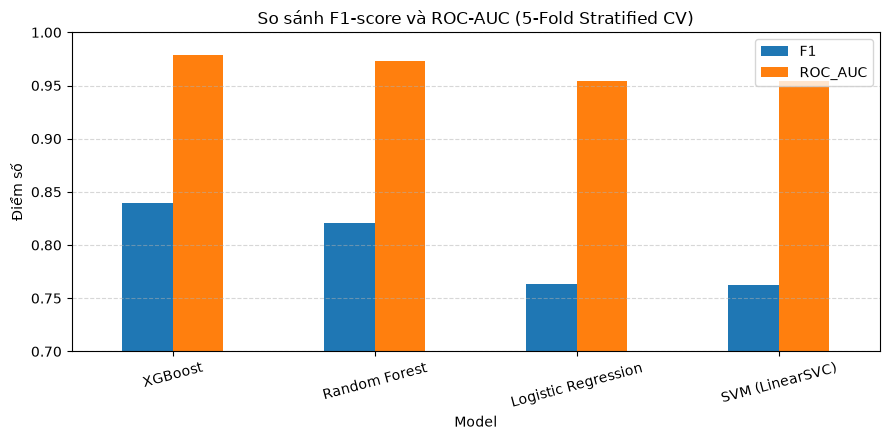

In [4]:
import matplotlib.pyplot as plt

results_df = pd.DataFrame(rows).sort_values("F1", ascending=False).reset_index(drop=True)
display(results_df)

ax = results_df.set_index("Model")[["F1", "ROC_AUC"]].plot(
    kind="bar", figsize=(9, 4.5), ylim=(0.7, 1.0), rot=15
)
plt.title("So sánh F1-score và ROC-AUC (5-Fold Stratified CV)")
plt.ylabel("Điểm số")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()